In [1]:
# %%
# ============= CELLULE 1: IMPORTS =============
import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import time
from tqdm import tqdm
import matplotlib.pyplot as plt

%matplotlib inline

# Ajout du path pour les fonctions YOLOP
sys.path.append(os.getcwd())
from lib.core.general import non_max_suppression, box_iou, ap_per_class
from lib.core.evaluate import SegmentationMetric


In [2]:

# Configuration globale
CONF_THRES = 0.001
IOU_THRES = 0.6
IMG_SIZE = 640


In [3]:

# %%
# ============= CELLULE 2: DatasetImage =============
class DatasetImage:
    """Classe pour traiter une seule image avec letterbox (comme le code de référence)"""
    
    def __init__(self, img_path, model_path=None):
        self.img_path = img_path
        self.model_path = model_path
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        # Chemins Ground Truth
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        # Session ONNX
        self.session = None
        
        # Résultats
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        
        # Infos letterbox
        self.r = None
        self.dw = None
        self.dh = None
        self.new_w = None
        self.new_h = None
        
        self.inference_time = 0
    
    def _get_gt_paths(self):
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path
    
    def _letterbox(self, img, new_shape=640):
        """Letterbox resize comme dans le code de référence"""
        shape = img.shape[:2]
        if isinstance(new_shape, int):
            new_shape = (new_shape, new_shape)
        
        # Ratio et nouvelles dimensions
        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
        
        # Padding
        dw = (new_shape[1] - new_unpad[0]) // 2
        dh = (new_shape[0] - new_unpad[1]) // 2
        
        # Resize
        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
        
        # Padding avec valeur 114
        top, bottom = dh, new_shape[0] - new_unpad[1] - dh
        left, right = dw, new_shape[1] - new_unpad[0] - dw
        img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        
        return img, r, dw, dh, new_unpad[0], new_unpad[1]
    
    def load_ground_truth(self):
        """Charge les GT avec binarisation (comme dans le code de référence)"""
        # 1. Masques de segmentation
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_da is not None:
                # ASTUCE CRITIQUE: Binarisation
                self.gt_da = (self.gt_da > 0).astype(np.uint8)
                if self.gt_da.shape != (self.h_orig, self.w_orig):
                    self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll is not None:
                # ASTUCE CRITIQUE: Binarisation
                self.gt_ll = (self.gt_ll > 0).astype(np.uint8)
                if self.gt_ll.shape != (self.h_orig, self.w_orig):
                    self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        # 2. Boîtes de détection (format: [class, x1, y1, x2, y2])
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') == 'car':
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    0,  # class_id (toujours 0 pour 'car')
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception as e:
                pass
        
        self.gt_boxes = np.array(self.gt_boxes) if len(self.gt_boxes) > 0 else np.zeros((0, 5))
    
    def run_inference(self):
        """Inférence avec letterbox (comme dans le code de référence)"""
        if self.session is None:
            providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
            self.session = ort.InferenceSession(self.model_path, providers=providers)
        
        # Letterbox preprocessing
        img_letterbox, self.r, self.dw, self.dh, self.new_w, self.new_h = self._letterbox(
            self.img_rgb, IMG_SIZE
        )
        
        # Normalisation
        img_input = img_letterbox.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)
        
        # Inférence
        start_time = time.time()
        outputs = self.session.run(
            ['det_out', 'drive_area_seg', 'lane_line_seg'], 
            {self.session.get_inputs()[0].name: img_input}
        )
        self.inference_time = (time.time() - start_time) * 1000  # ms
        
        det_out, da_seg_out, ll_seg_out = outputs
        
        # === SEGMENTATION (avec crop du padding) ===
        # Prendre argmax pour avoir les classes
        da_pred = np.argmax(da_seg_out, axis=1)[0]  # (640, 640)
        ll_pred = np.argmax(ll_seg_out, axis=1)[0]
        
        # Retirer le padding (comme dans le code de référence)
        da_pred = da_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        ll_pred = ll_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        
        # Resize vers taille originale
        self.pred_da = cv2.resize(da_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        
        # === DETECTION (avec correction letterbox) ===
        det_tensor = torch.from_numpy(det_out).float()
        nms_out = non_max_suppression(det_tensor, conf_thres=CONF_THRES, iou_thres=IOU_THRES)
        
        if nms_out[0] is not None and len(nms_out[0]) > 0:
            pred_boxes = nms_out[0].cpu().numpy()
            
            # Correction letterbox (comme dans le code de référence)
            pred_boxes[:, [0, 2]] -= self.dw
            pred_boxes[:, [1, 3]] -= self.dh
            pred_boxes[:, :4] /= self.r
            
            # Clamp aux dimensions originales
            pred_boxes[:, 0] = np.clip(pred_boxes[:, 0], 0, self.w_orig)
            pred_boxes[:, 2] = np.clip(pred_boxes[:, 2], 0, self.w_orig)
            pred_boxes[:, 1] = np.clip(pred_boxes[:, 1], 0, self.h_orig)
            pred_boxes[:, 3] = np.clip(pred_boxes[:, 3], 0, self.h_orig)
            
            self.pred_boxes = pred_boxes
        else:
            self.pred_boxes = np.zeros((0, 6))


    def visualize(self):
        """Génère la visualisation : Originale | GT | Prédiction"""
        def draw_overlay(img, da, ll, boxes, box_type='pred', color=(0, 255, 0)):
            res = img.copy()
            # 1. Segmentation (Transparence)
            color_mask = np.zeros_like(res)
            if da is not None: color_mask[da == 1] = [0, 255, 0] # Vert pour Route
            if ll is not None: color_mask[ll == 1] = [255, 0, 0] # Rouge pour Ligne
            
            mask_indices = np.any(color_mask != 0, axis=-1)
            res[mask_indices] = res[mask_indices] * 0.6 + color_mask[mask_indices] * 0.4
            
            # 2. Détection (Boîtes)
            if boxes is not None and len(boxes) > 0:
                for box in boxes:
                    # GT format: [cls, x1, y1, x2, y2]
                    # Pred format: [x1, y1, x2, y2, conf, cls]
                    if box_type == 'gt': x1, y1, x2, y2 = map(int, box[1:5])
                    else: x1, y1, x2, y2 = map(int, box[:4])
                    
                    cv2.rectangle(res, (x1, y1), (x2, y2), color, 2)
            return res

        # Création des images
        viz_gt = draw_overlay(self.img_rgb, self.gt_da, self.gt_ll, self.gt_boxes, 'gt', (255, 255, 0)) # Jaune
        viz_pred = draw_overlay(self.img_rgb, self.pred_da, self.pred_ll, self.pred_boxes, 'pred', (0, 140, 255)) # Orange

        # Affichage Matplotlib
        plt.figure(figsize=(24, 8))
        
        plt.subplot(1, 3, 1)
        plt.imshow(self.img_rgb)
        plt.title("Image Originale")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(viz_gt)
        plt.title("Réalité Terrain (GT)\n(Jaune=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(viz_pred)
        plt.title("Prédiction Modèle\n(Orange=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')
        
        plt.tight_layout()
        plt.show()



In [4]:

# %%
# ============= CELLULE 3: DatasetFull =============
class DatasetFull:
    """Évaluation complète du dataset avec méthodes du code de référence"""
    
    def __init__(self, img_dir, model_path, max_images=None):
        self.img_dir = img_dir
        self.model_path = model_path
        
        self.image_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
        if max_images:
            self.image_files = self.image_files[:max_images]
        
        print(f"Dataset: {len(self.image_files)} images")
        
        # Métriques (utilise les classes du code de référence)
        self.da_metric = SegmentationMetric(2)  # 2 classes: background, road
        self.ll_metric = SegmentationMetric(2)  # 2 classes: background, lane
        
        # Detection stats (pour ap_per_class)
        self.det_stats = []
        
        # IoU thresholds (comme dans le code de référence)
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.iouv = torch.linspace(0.5, 0.95, 10).to(device)
        self.niou = self.iouv.numel()
        self.device = device
        
        self.times = []
    
    def process_all(self):
        """Traitement de toutes les images"""
        print(" Évaluation en cours...")
        
        for img_name in tqdm(self.image_files):
            img_path = os.path.join(self.img_dir, img_name)
            
            try:
                img_obj = DatasetImage(img_path, self.model_path)
                img_obj.load_ground_truth()
                img_obj.run_inference()
                
                # 1. Speed
                self.times.append(img_obj.inference_time)
                
                # 2. Segmentation (avec SegmentationMetric comme le code de référence)
                if img_obj.pred_da is not None and img_obj.gt_da is not None:
                    self.da_metric.addBatch(img_obj.pred_da, img_obj.gt_da)
                
                if img_obj.pred_ll is not None and img_obj.gt_ll is not None:
                    self.ll_metric.addBatch(img_obj.pred_ll, img_obj.gt_ll)
                
                # 3. Detection (calcul des stats pour ap_per_class)
                self._process_detection_stats(img_obj)
                
            except Exception as e:
                print(f"Erreur {img_name}: {e}")
    
    def _process_detection_stats(self, img_obj):
        """Calcule les stats de détection (comme dans le code de référence)"""
        pred = torch.from_numpy(img_obj.pred_boxes).float().to(self.device)
        labels = torch.from_numpy(img_obj.gt_boxes).float().to(self.device)
        
        nl = len(labels)
        tcls = labels[:, 0].tolist() if nl else []
        
        if len(pred) == 0:
            if nl:
                self.det_stats.append((
                    torch.zeros(0, self.niou, dtype=torch.bool),
                    torch.Tensor(),
                    torch.Tensor(),
                    tcls
                ))
            return
        
        # Calcul IoU et matching (comme dans le code de référence)
        correct = torch.zeros(pred.shape[0], self.niou, dtype=torch.bool, device=self.device)
        
        if nl:
            detected = []
            tcls_tensor = labels[:, 0]
            tbox = labels[:, 1:5]
            
            for cls in torch.unique(tcls_tensor):
                ti = (tcls_tensor == cls).nonzero(as_tuple=False).view(-1)
                pi = (pred[:, 5] == cls).nonzero(as_tuple=False).view(-1)
                
                if pi.shape[0]:
                    # Calcul IoU
                    ious, idx = box_iou(pred[pi, :4], tbox[ti]).max(1)
                    
                    # Match detections to ground truth
                    for j in (ious > self.iouv[0]).nonzero(as_tuple=False):
                        d = ti[idx[j]]
                        if d.item() not in detected:
                            detected.append(d.item())
                            correct[pi[j]] = ious[j] > self.iouv
                            if len(detected) == nl:
                                break
        
        self.det_stats.append((
            correct.cpu(),
            pred[:, 4].cpu(),
            pred[:, 5].cpu(),
            tcls
        ))
    
    def compute_metrics(self):
        """Calcul des métriques finales au format YOLOP officiel"""
        print("\n" + "="*60)
        print("YOLOP EVALUATION RESULTS")
        print("="*60)
        
        # === SPEED (calculé une fois pour tous) ===
        avg_time = np.mean(self.times)
        fps = 1000 / avg_time if avg_time > 0 else 0
        
        # === DETECTION ===
        recall_val = 0.0
        map50_val = 0.0
        
        if len(self.det_stats):
            stats = [np.concatenate(x, 0) for x in zip(*self.det_stats)]
            
            if stats[0].any():
                # Utilise ap_per_class du code de référence
                p, r, ap, f1, ap_class = ap_per_class(
                    *stats, plot=False, save_dir=None, names={0: 'car'}
                )
                ap50 = ap[:, 0]
                
                recall_val = r.mean()
                map50_val = ap50.mean()
        
        print("Traffic Object Detection Result")
        print(f"    Recall(%): {recall_val*100:.2f}")
        print(f"    Speed(fps): {fps:.2f}")
        print(f"    mAP50(%): {map50_val*100:.2f}")
        
        # === DRIVABLE AREA SEGMENTATION ===
        da_miou = self.da_metric.meanIntersectionOverUnion()
        
        print("Drivable Area Segmentation Result")
        print(f"    mIOU(%): {da_miou*100:.2f}")
        print(f"    Speed(fps): {fps:.2f}")
        
        # === LANE DETECTION ===
        ll_miou = self.ll_metric.meanIntersectionOverUnion()
        ll_iou = self.ll_metric.IntersectionOverUnion()
        
        print("Lane Detection Result")
        print(f"    mIOU(%): {ll_miou*100:.2f}")
        print(f"    IOU(%): {ll_iou*100:.2f}")
        
        print("="*60)



  DIAGNOSTIC MATÉRIEL
 PyTorch utilise : CUDA (GPU)


/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:234: UserWarning: 
NVIDIA GeForce RTX 5060 Ti with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_52 sm_60 sm_61 sm_70 sm_72 sm_75 sm_80 sm_86 sm_87 sm_90 compute_90.
If you want to use the NVIDIA GeForce RTX 5060 Ti GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


   Carte Graphique : NVIDIA GeForce RTX 5060 Ti
   Mémoire VRAM    : 16.61 GB
----------------------------------------
 ONNX Runtime Providers disponibles :
 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
 ONNX peut utiliser le GPU (CUDA détecté).

Dataset: 10000 images
 Évaluation en cours...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [19:35<00:00,  8.51it/s]



YOLOP EVALUATION RESULTS
Traffic Object Detection Result
    Recall(%): 89.11
    Speed(fps): 46.84
    mAP50(%): 71.94
Drivable Area Segmentation Result
    mIOU(%): 91.24
    Speed(fps): 46.84
Lane Detection Result
    mIOU(%): 59.54
    IOU(%): 20.70

============================== VISUALISATION D'UNE IMAGE ==============================


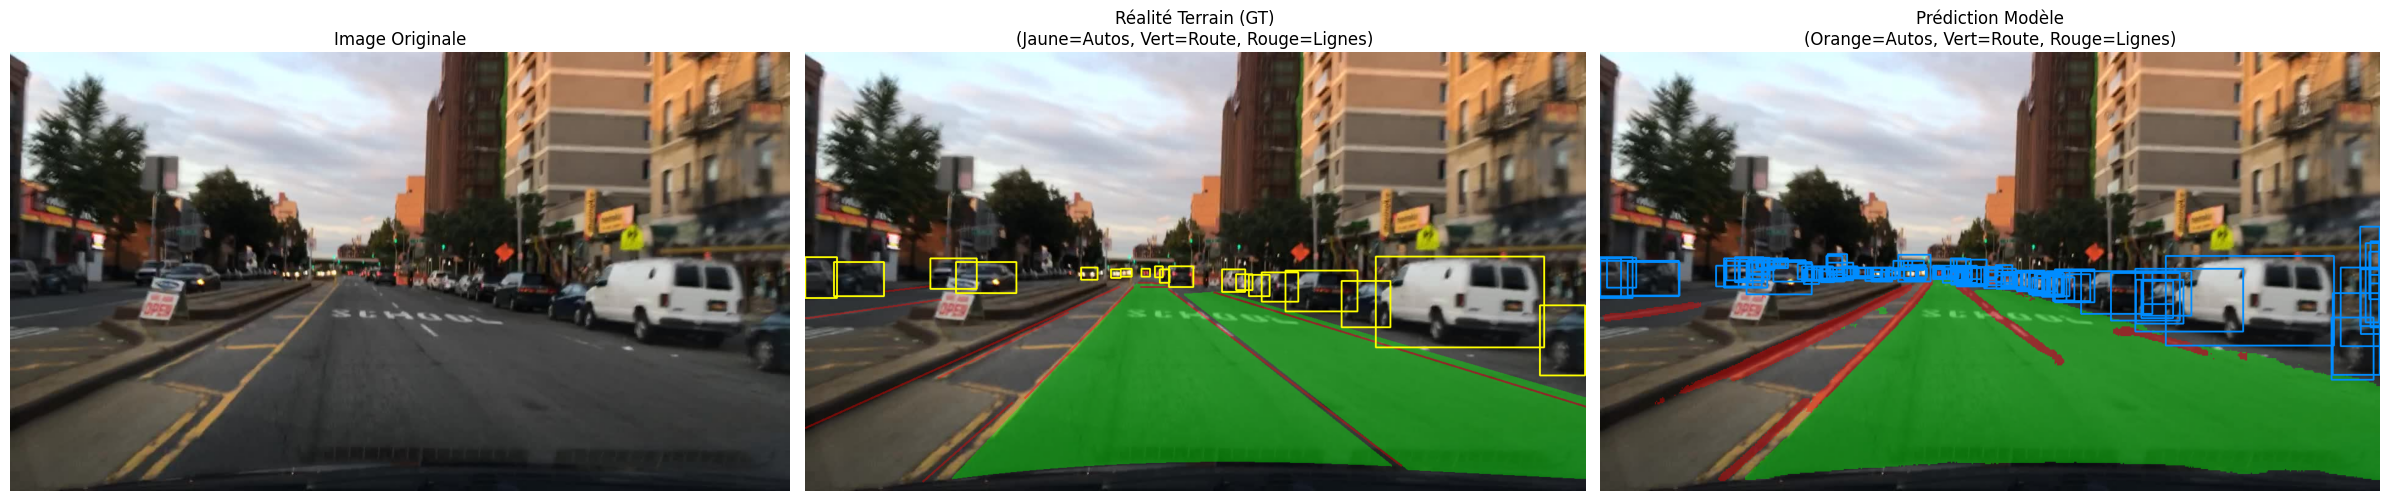

Visualisation générée pour : b1c66a42-6f7d68ca.jpg


In [5]:
# %%
# ==========================================
# CELLULE 4 : MAIN & DIAGNOSTIC
# ==========================================
if __name__ == "__main__":
    # --- 1. DIAGNOSTIC MATÉRIEL ---
    print("\n" + "="*40)
    print("  DIAGNOSTIC MATÉRIEL")
    print("="*40)
    
    # Check PyTorch
    if torch.cuda.is_available():
        print(f" PyTorch utilise : CUDA (GPU)")
        print(f"   Carte Graphique : {torch.cuda.get_device_name(0)}")
        print(f"   Mémoire VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    else:
        print(f" PyTorch utilise : CPU")
    
    # Check ONNX Runtime
    print("-" * 40)
    providers = ort.get_available_providers()
    print(f" ONNX Runtime Providers disponibles :\n {providers}")
    
    if 'CUDAExecutionProvider' in providers:
        print(" ONNX peut utiliser le GPU (CUDA détecté).")
    else:
        print(" ONNX ne détecte PAS CUDA. Il tournera sur CPU.")
    print("="*40 + "\n")

    # --- 2. CONFIGURATION ---
    VAL_DIR = "dataset/images/val"
    ONNX_PATH = "weights/yolop-640-640.onnx"
    MAX_IMAGES = None  # Nombre d'images à évaluer
    
    # --- 3. LANCEMENT ---
    if not os.path.exists(VAL_DIR):
        print(f"Dossier introuvable: {VAL_DIR}")
    elif not os.path.exists(ONNX_PATH):
        print(f"Modèle introuvable: {ONNX_PATH}")
    else:
        # Évaluation Globale
        evaluator = DatasetFull(VAL_DIR, ONNX_PATH, max_images=MAX_IMAGES)
        evaluator.process_all()
        evaluator.compute_metrics()
        
        # Visualisation d'une image spécifique
        print("\n" + "="*30 + " VISUALISATION D'UNE IMAGE " + "="*30)
        TARGET_IMG = "b1c66a42-6f7d68ca.jpg" 
        target_path = os.path.join(VAL_DIR, TARGET_IMG)
        
        if os.path.exists(target_path):
            try:
                vis_obj = DatasetImage(target_path, ONNX_PATH)
                vis_obj.load_ground_truth()
                vis_obj.run_inference()
                vis_obj.visualize()
                print(f"Visualisation générée pour : {TARGET_IMG}")
            except Exception as e:
                print(f"Erreur visualisation : {e}")
        else:
            print(f"Image cible introuvable : {target_path}")